# 01 · Exploração dos dados

Os **Dados Estatísticos do Transporte Aéreo** da ANAC têm uma linha por empresa × origem × destino × mês × grupo de voo.
Este notebook mostra os padrões que orientam a modelagem: concentração em voos regulares, tendência, sazonalidade
e o choque da COVID.

> Pré-requisito: `anac-demanda tudo` (ou ao menos `anac-demanda explorar`) na raiz do projeto.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from anac_demanda.config import carregar_config
from anac_demanda.data import carregar_dados
from anac_demanda.features import carregar_painel

cfg = carregar_config()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = cfg.dir_figuras

In [2]:
df = carregar_dados(cfg)
print(f"{len(df):,} registros · {df['empresa_sigla'].nunique()} empresas · "
      f"{df['ano'].min()}-01 a {df['ano'].max()}-{df.loc[df['ano'] == df['ano'].max(), 'mes'].max():02d}")
df.sample(5, random_state=1)

1,087,033 registros · 322 empresas · 2000-01 a 2026-04


,empresa_sigla,empresa_nacionalidade,aeroporto_de_origem_sigla,aeroporto_de_origem_uf,aeroporto_de_origem_regiao,aeroporto_de_origem_pais,aeroporto_de_destino_sigla,aeroporto_de_destino_uf,aeroporto_de_destino_regiao,aeroporto_de_destino_pais,natureza,grupo_de_voo,ano,mes,passageiros_pagos,assentos,decolagens,distancia_voada_km
116157,RSL,BRASILEIRA,SBGR,SP,SUDESTE,BRASIL,SBMO,AL,NORDESTE,BRASIL,DOMÉSTICA,NÃO REGULAR,2002,11,66.000,117.000,1.000,"1,920.000"
778765,TAM,BRASILEIRA,SBSL,MA,NORDESTE,BRASIL,SBGR,SP,SUDESTE,BRASIL,DOMÉSTICA,REGULAR,2017,1,"9,894.000","11,620.000",57.000,"132,867.000"
366025,ONE,BRASILEIRA,SBGR,SP,SUDESTE,BRASIL,SBCH,SC,SUL,BRASIL,DOMÉSTICA,NÃO REGULAR,2008,3,27.000,100.000,1.000,746.000
479303,GEC,ESTRANGEIRA,SBEG,AM,NORTE,BRASIL,TJBQ,<NA>,<NA>,PORTO RICO,INTERNACIONAL,REGULAR,2011,4,0.000,NaN,NaN,NaN
791302,AZU,BRASILEIRA,SBCF,MG,SUDESTE,BRASIL,SBHT,PA,NORTE,BRASIL,DOMÉSTICA,IMPRODUTIVO,2018,3,0.000,NaN,NaN,NaN


## Voos regulares concentram quase todos os passageiros

Por isso o modelo trata só o grupo `REGULAR`; voos fretados e não regulares têm dinâmica própria e volume pequeno.

In [3]:
(df.groupby("grupo_de_voo", dropna=False)["passageiros_pagos"].sum()
   .pipe(lambda s: s / s.sum()).sort_values(ascending=False).map("{:.2%}".format))

grupo_de_voo
REGULAR             96.31%
NÃO REGULAR          3.66%
IMPRODUTIVO          0.04%
NÃO IDENTIFICADO     0.00%
<NA>                 0.00%
Name: passageiros_pagos, dtype: str

## Tendência e o choque da COVID

Queda 2019 → 2020: 57.0%  ·  2025 vs. 2019: 109.6%


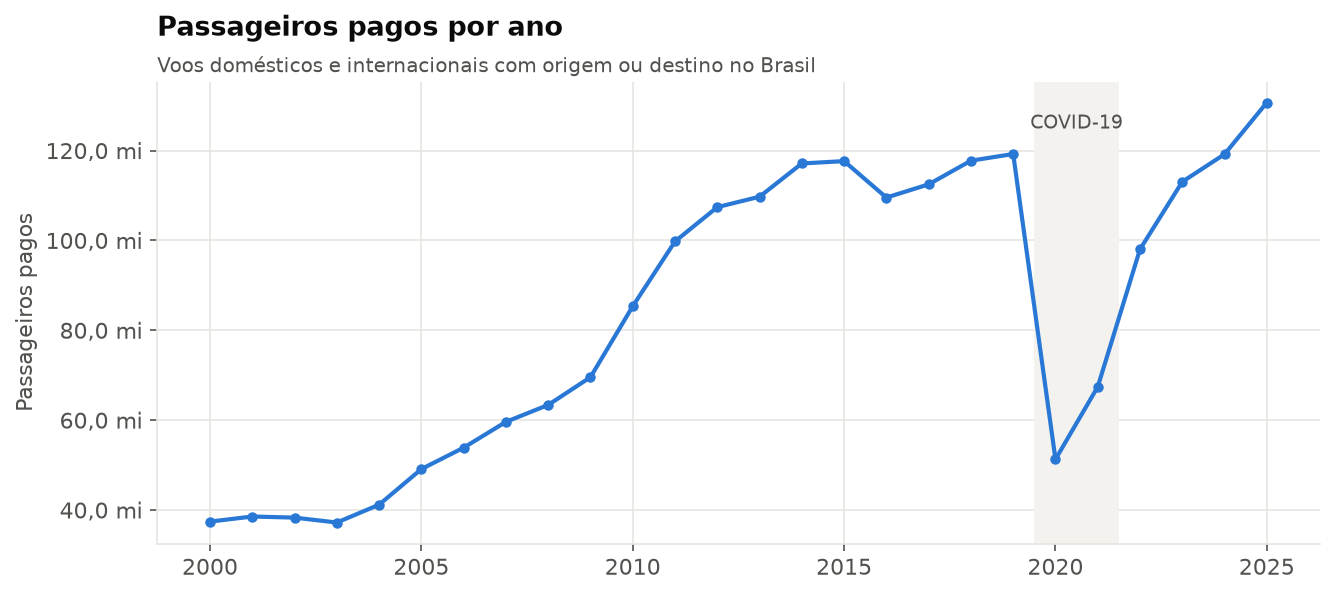

In [4]:
anual = df.groupby("ano")["passageiros_pagos"].sum()
print(f"Queda 2019 → 2020: {1 - anual[2020] / anual[2019]:.1%}  ·  2025 vs. 2019: {anual[2025] / anual[2019]:.1%}")
display(Image(FIG / "eda_passageiros_por_ano.png", width=780))

## Sazonalidade

Janeiro, julho e dezembro ficam acima da média do ano; fevereiro é o vale. As viradas entre esses meses são onde uma previsão ingênua ("o mês que vem será igual a este") mais erra.

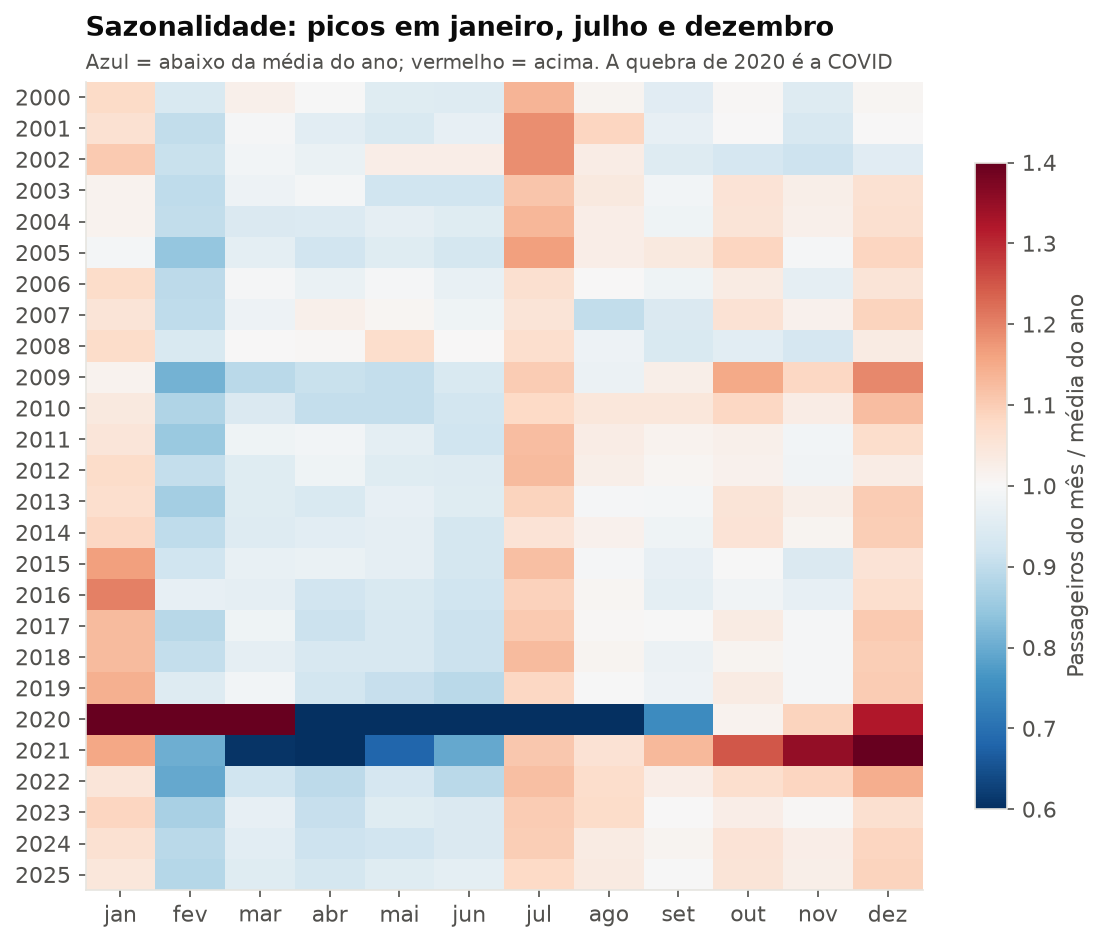

In [5]:
display(Image(FIG / "eda_sazonalidade.png", width=640))

## Concentração do mercado e principais rotas

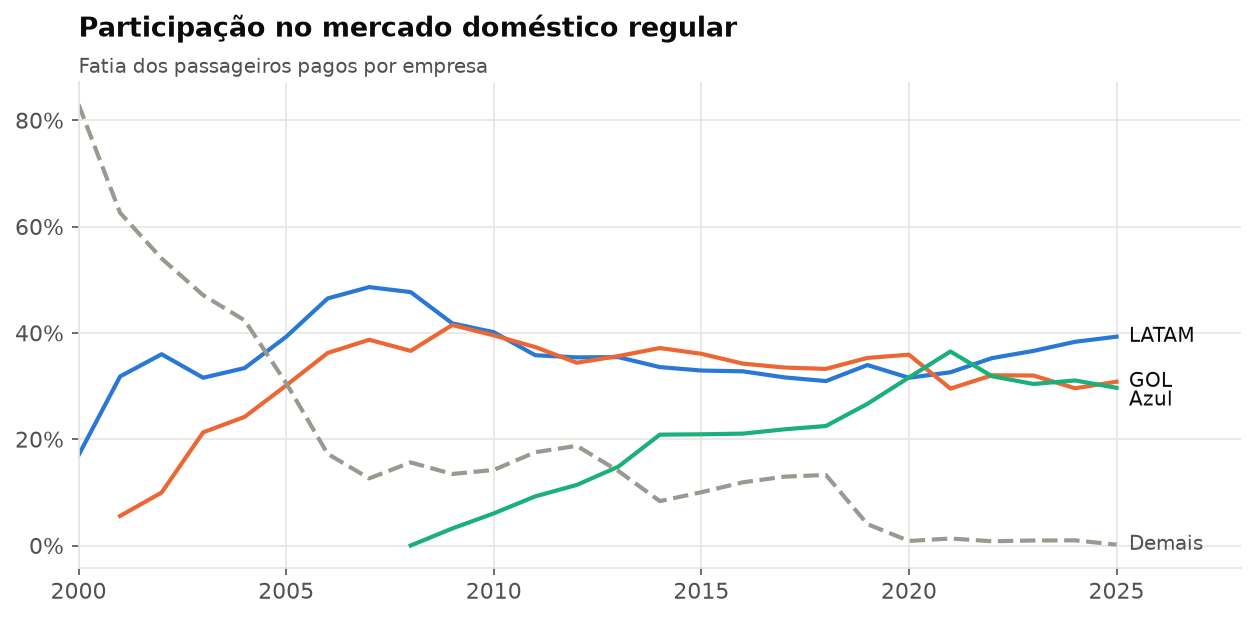

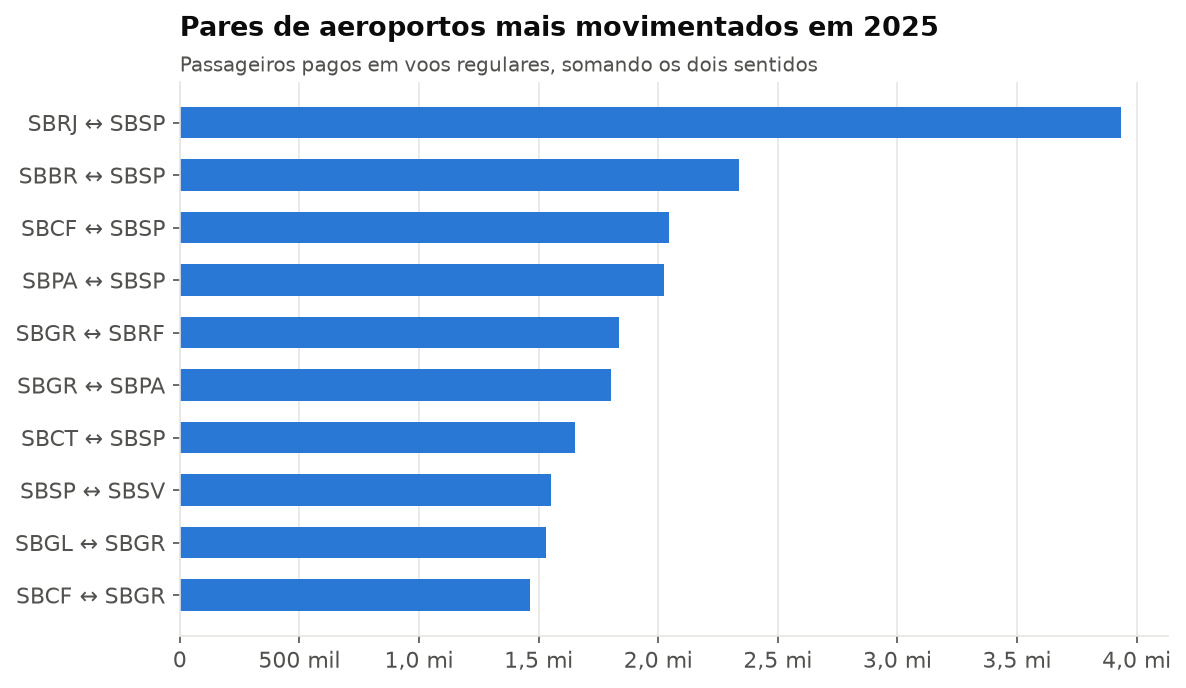

In [6]:
display(Image(FIG / "eda_participacao_empresas.png", width=780))
display(Image(FIG / "eda_top_rotas.png", width=640))

## Do registro à série temporal

Agregando os voos regulares por empresa + origem + destino + mês, cada rota vira uma série mensal. Rotas aparecem,
somem e voltam; o painel de features considera isso (idade da rota, meses ativos nos últimos 12, alvo zero quando a
rota para).

In [7]:
painel = carregar_painel(cfg)
por_rota = painel.groupby("serie_id").size()
print(f"{painel['serie_id'].nunique():,} rotas · mediana de {por_rota.median():.0f} meses ativos por rota")
print(f"{(painel['alvo'] == 0).mean():.1%} das linhas têm alvo zero (a rota não operou no mês seguinte)")
painel[["empresa_sigla", "aeroporto_de_origem_sigla", "aeroporto_de_destino_sigla", "ano_alvo", "mes_alvo",
        "pax_lag0", "pax_lag11", "pax_media_3m", "ocupacao_lag0", "alvo"]].sample(6, random_state=3)

18,085 rotas · mediana de 10 meses ativos por rota
7.1% das linhas têm alvo zero (a rota não operou no mês seguinte)


,empresa_sigla,aeroporto_de_origem_sigla,aeroporto_de_destino_sigla,ano_alvo,mes_alvo,pax_lag0,pax_lag11,pax_media_3m,ocupacao_lag0,alvo
133250,TAM,SBCT,SBPA,2005,5,"5,692.000","5,130.000","5,263.667",0.538,"5,283.000"
74831,VSP,SBGL,SBFI,2002,10,"1,153.000","1,527.000","1,120.333",NaN,"1,162.000"
367307,ONE,SBBR,SBCF,2014,8,"2,424.000","2,700.000","2,346.333",0.782,"2,592.000"
325854,AZU,SBSL,SBCF,2013,1,"4,416.000","4,525.000","3,694.333",0.680,"4,649.000"
115200,VSP,SBIL,SBGR,2004,7,149.000,172.000,145.667,1.393,212.000
139304,TIB,SBCA,SBPP,2005,8,50.000,0.000,28.000,0.104,58.000
